In [2]:
%pip install -q xgboost lightgbm catboost

In [3]:
import pandas as pd
import numpy as np

import time

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from catboost import CatBoostClassifier

import warnings
warnings.filterwarnings("ignore")

SEED = 42

Load The Data


In [5]:
train = pd.read_csv("train (2).csv")
train.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


EDA on The Dataset

In [6]:
print("Shape:", train.shape)

print("\nColumns:")
print(train.columns.tolist())

print("\nData types:")
print(train.dtypes)

print("\nMissing values:")
print(train.isnull().sum().sort_values(ascending=False).head(20))

print("\nTarget distribution:")
print(train["is_fraud"].value_counts())

print("\nTarget proportion:")
print(train["is_fraud"].value_counts(normalize=True))

Shape: (157030, 26)

Columns:
['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes', 'merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt', 'is_fraud']

Data types:
id                                int64
amount_usd                      float64
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week               

Separate X and y

In [7]:
TARGET = "is_fraud"

# Drop target and ID from model features
drop_cols = [TARGET]

if "id" in train.columns:
    drop_cols.append("id")

X = train.drop(columns=drop_cols)
y = train[TARGET]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (157030, 24)
y shape: (157030,)


Stratified train/validation spli

In [10]:
# Run the Stratified train/validation split again
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Validation shape:", X_valid.shape)

print("\nTrain target proportions:")
print(y_train.value_counts(normalize=True))

print("\nValidation target proportions:")
print(y_valid.value_counts(normalize=True))

Train shape: (125623, 24)
Validation shape: (31406, 24)

Train target proportions:
is_fraud
0.0    0.983848
1.0    0.016152
Name: proportion, dtype: float64

Validation target proportions:
is_fraud
0.0    0.983857
1.0    0.016143
Name: proportion, dtype: float64


Preprocessing

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_cols = X_train.select_dtypes(include="number").columns.tolist()

categorical_cols = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

# Ensure all categorical columns are explicitly converted to string to handle mixed types (bool, string, object, NaN)
for col in categorical_cols:
    X_train[col] = X_train[col].astype(str)
    X_valid[col] = X_valid[col].astype(str)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            SimpleImputer(strategy="median"),
            numeric_cols
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            categorical_cols
        )
    ],
    remainder="drop"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_valid_processed = preprocessor.transform(X_valid)

print("Processed train:", X_train_processed.shape)
print("Processed validation:", X_valid_processed.shape)

Processed train: (125623, 60)
Processed validation: (31406, 60)


Define compare_boosters :

This is the benchmarking function. It trains the three models, applies early stopping, and returns a table with ROC-AUC, best iteration and elapsed time.

In [14]:
def compare_boosters(
    X_train,
    y_train,
    X_valid,
    y_valid
):
    results = []

    models = {
        "XGBoost": XGBClassifier(
            n_estimators=1500,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="auc",
            early_stopping_rounds=100,
            tree_method="hist",
            random_state=SEED,
            n_jobs=-1
        ),

        "LightGBM": LGBMClassifier(
            n_estimators=1500,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=-1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=SEED,
            n_jobs=-1,
            verbosity=-1
        ),

        "CatBoost": CatBoostClassifier(
            iterations=1500,
            learning_rate=0.05,
            depth=6,
            loss_function="Logloss",
            eval_metric="AUC",
            random_seed=SEED,
            verbose=False
        )
    }

    for name, model in models.items():

        print(f"\nTraining {name}...")

        start_time = time.perf_counter()

        if name == "XGBoost":

            model.fit(
                X_train,
                y_train,
                eval_set=[(X_valid, y_valid)],
                verbose=False
            )

            best_iteration = model.best_iteration + 1

        elif name == "LightGBM":

            model.fit(
                X_train,
                y_train,
                eval_set=[(X_valid, y_valid)],
                callbacks=[
                    early_stopping(100, verbose=False),
                    log_evaluation(0)
                ]
            )

            best_iteration = model.best_iteration_

        elif name == "CatBoost":

            model.fit(
                X_train,
                y_train,
                eval_set=(X_valid, y_valid),
                early_stopping_rounds=100,
                verbose=False
            )

            best_iteration = model.get_best_iteration() + 1

        elapsed_time = time.perf_counter() - start_time

        # Predict probabilities for positive class
        predictions = model.predict_proba(X_valid)[:, 1]

        score = roc_auc_score(y_valid, predictions)

        results.append({
            "Model": name,
            "Validation ROC-AUC": score,
            "Best Iteration": best_iteration,
            "Time (seconds)": elapsed_time
        })

        print(f"ROC-AUC: {score:.5f}")
        print(f"Best iteration: {best_iteration}")
        print(f"Time: {elapsed_time:.2f} seconds")

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        by="Validation ROC-AUC",
        ascending=False
    ).reset_index(drop=True)

    return results_df

Run the benchmark

In [15]:
results = compare_boosters(
    X_train_processed,
    y_train,
    X_valid_processed,
    y_valid
)

results


Training XGBoost...
ROC-AUC: 0.94224
Best iteration: 148
Time: 15.65 seconds

Training LightGBM...
ROC-AUC: 0.94315
Best iteration: 169
Time: 7.99 seconds

Training CatBoost...
ROC-AUC: 0.94443
Best iteration: 440
Time: 24.14 seconds


,Model,Validation ROC-AUC,Best Iteration,Time (seconds)
0,CatBoost,0.944426,440,24.140790
1,LightGBM,0.943152,169,7.988859
2,XGBoost,0.942245,148,15.650492


Identify fastest and best

In [16]:
best_model = results.iloc[0]

fastest_model = results.loc[
    results["Time (seconds)"].idxmin()
]

print("Best model:")
print(best_model["Model"])
print("ROC-AUC:", round(best_model["Validation ROC-AUC"], 5))

print("\nFastest model:")
print(fastest_model["Model"])
print("Time:", round(fastest_model["Time (seconds)"], 2), "seconds")

Best model:
CatBoost
ROC-AUC: 0.94443

Fastest model:
LightGBM
Time: 7.99 seconds


Compare score differences

In [17]:
results["AUC Difference from Best"] = (
    results["Validation ROC-AUC"].max()
    - results["Validation ROC-AUC"]
)

results

,Model,Validation ROC-AUC,Best Iteration,Time (seconds),AUC Difference from Best
0,CatBoost,0.944426,440,24.140790,0.000000
1,LightGBM,0.943152,169,7.988859,0.001274
2,XGBoost,0.942245,148,15.650492,0.002181


Visualize comparison

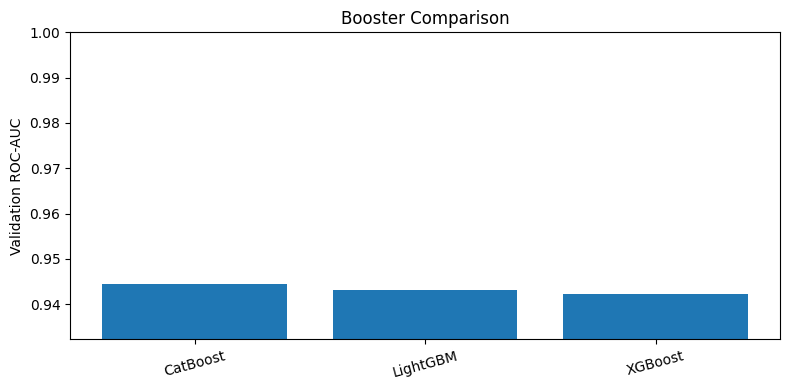

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.bar(
    results["Model"],
    results["Validation ROC-AUC"]
)

plt.ylabel("Validation ROC-AUC")
plt.title("Booster Comparison")
plt.ylim(
    results["Validation ROC-AUC"].min() - 0.01,
    1.0
)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [19]:
results.to_csv("booster_benchmark_results.csv", index=False)

print("Saved benchmark results.")

Saved benchmark results.
